# MNIST digit classification with NumPy

Explore data preparation, neural network training, test-set evaluation, and single-image prediction. Run the cells in order.

## 1. Import the tools

`Dataset` prepares MNIST, NumPy handles numerical arrays, and Matplotlib displays images and learning curves.

In [1]:
from mnist_dataset import Dataset 

import numpy as np
import matplotlib.pyplot as plt

## 2. Load MNIST

Select `n_train` training images and `n_test` test images. The loader shuffles each split, normalizes pixel values (from 0-255 to 0-1), flattens each 28 x 28 image into 784 values, and converts labels to one-hot vectors.

In [2]:
Data = Dataset(n_train=1000, n_test=100)

### Understand the data shapes

Each **column** represents one image. Training inputs have shape `(784, 1000)` and test inputs have shape `(784, 100)`. Labels have 10 rows for digits 0-9, with a 1 in the correct class for each image.

In [3]:
X_train, Y_train, X_test, Y_test = Data.get_mnist_data()
print(f"Model input-dimensions: {Data.input_dim}")
print(f"Number of classes: {Data.n_classes}")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Y_train shape: {Y_train.shape}")
print(f"Y_test shape: {Y_test.shape}")

Model input-dimensions: 784
Number of classes: 10
X_train shape: (784, 1000)
X_test shape: (784, 100)
Y_train shape: (10, 1000)
Y_test shape: (10, 100)


### Inspect a training example

`X_train[:, 0]` selects the first image; reshaping to `(28, 28)` restores its layout for display. `np.argmax(Y_train[:, 0])` converts the one-hot label back to its digit. `X_train[0]`, by contrast, selects the first pixel across all training examples, giving shape `(1000,)`.

X_train[0] shape: (1000,)


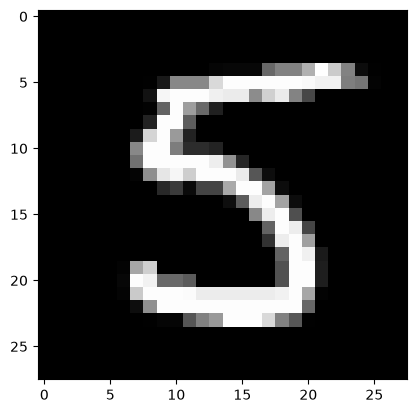

Label: 5
Label one-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [4]:
print(f"X_train[0] shape: {X_train[0].shape}")
plt.imshow(X_train[:, 0].reshape(28, 28), cmap='gray')
plt.show()
print(f"Label: {np.argmax(Y_train[:,0])}")
print(f"Label one-hot: {Y_train[:,0]}")

## 3. Configure the model

The network maps 784 input pixels through 10 hidden ReLU neurons to 10 softmax output probabilities. The learning rate of `0.1` controls update size; `1000` epochs specifies 1,000 passes over the training data.

In [5]:
from model_gd import Model

model = Model(learning_rate=0.1, epochs=1000)

## 4. Train the neural network

Each epoch runs forward propagation, computes gradients with backpropagation, and updates `W1`, `b1`, `W2`, and `b2` using full-batch gradient descent. Cross-entropy loss measures prediction error, while accuracy measures the fraction of correctly classified training images. Random initialization and shuffled samples can change the results between runs.

In [ ]:
model.train(X_train, Y_train)

## 5. Evaluate the test set

Use held-out images to measure generalization. Evaluation performs forward propagation with the trained parameters, selects the largest probability for each image, and compares predictions with the true labels. No parameters are updated. Accuracy is a fraction: `0.81` means 81% correct.

In [ ]:
test_acc = model.test(X_test=X_test, Y_test=Y_test)
print("Test accuracy: ", test_acc)

## 6. Predict one image

Restore the first test image to `(28, 28)` for display. `predict` flattens it into a `(784, 1)` column and returns the predicted digit and ten class probabilities. The printed percentage is the probability assigned to the predicted digit; it does not guarantee correctness.

Test images are already normalized. For an external grayscale image with pixel values from 0-255, divide by 255 once and use a light digit on a dark background, as in MNIST.

In [ ]:
test_image = X_test[:, 0].reshape(28,28)

prediction = model.predict(test_image)
print("--------------")
print("prediction: ", prediction[0])
print(f"probability: {prediction[1][prediction[0]]*100:.2f}%")
plt.imshow(test_image, cmap='gray')

## 7. Record learning curves (Optional)

With `track_data=True`, training returns four histories: training loss, training accuracy, test loss, and test accuracy. Providing `Testset` enables the test histories. Calling `train` again initializes new parameters and starts a fresh training run. If you use these curves to tune the model, use a validation split and reserve the test set for final evaluation.

In [6]:
train_loss, train_acc, test_loss, test_acc = model.train(X_train, Y_train, track_data=True, Testset=(X_test, Y_test))

Input dim: 784, Output dim: 10
Epoch 0: Loss = 3.4955, Accuracy = 0.1400
Epoch 20: Loss = 1.9681, Accuracy = 0.3370
Epoch 40: Loss = 1.5690, Accuracy = 0.4610
Epoch 60: Loss = 1.2835, Accuracy = 0.5540
Epoch 80: Loss = 1.0905, Accuracy = 0.6260
Epoch 100: Loss = 0.9535, Accuracy = 0.6790
Epoch 120: Loss = 0.8511, Accuracy = 0.7160
Epoch 140: Loss = 0.7707, Accuracy = 0.7470
Epoch 160: Loss = 0.7066, Accuracy = 0.7670
Epoch 180: Loss = 0.6538, Accuracy = 0.7850
Epoch 200: Loss = 0.6097, Accuracy = 0.7940
Epoch 220: Loss = 0.5721, Accuracy = 0.8080
Epoch 240: Loss = 0.5393, Accuracy = 0.8180
Epoch 260: Loss = 0.5101, Accuracy = 0.8320
Epoch 280: Loss = 0.4839, Accuracy = 0.8420
Epoch 300: Loss = 0.4597, Accuracy = 0.8530
Epoch 320: Loss = 0.4374, Accuracy = 0.8600
Epoch 340: Loss = 0.4165, Accuracy = 0.8620
Epoch 360: Loss = 0.3967, Accuracy = 0.8700
Epoch 380: Loss = 0.3785, Accuracy = 0.8760
Epoch 400: Loss = 0.3621, Accuracy = 0.8820
Epoch 420: Loss = 0.3468, Accuracy = 0.8880
Epoch 4

### Compare training and test performance

Plot loss and accuracy against epoch number. Falling loss and rising accuracy indicate learning. If training performance keeps improving while test performance worsens, the model may be overfitting. The legends distinguish training and test curves on each plot.

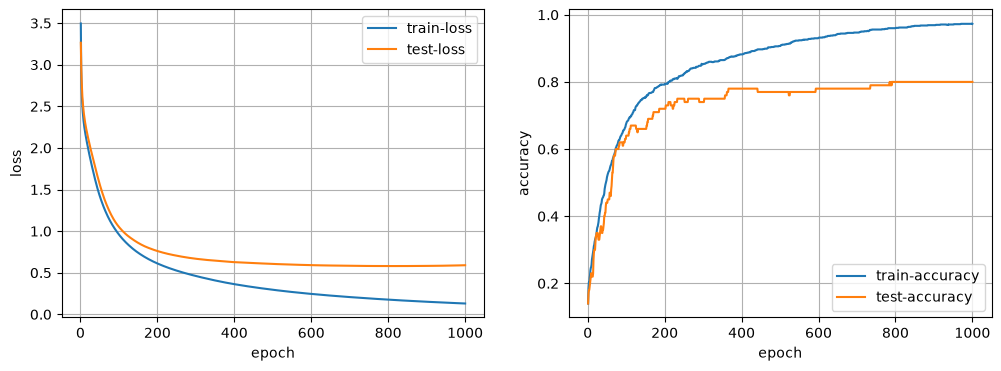

In [ ]:
epochs = np.arange(1,len(train_loss)+1)

fig, axis = plt.subplots(1,2, figsize=(12,4))
axis[0].plot(epochs, train_loss, label='train-loss')
axis[0].plot(epochs, test_loss, label='test-loss')
axis[1].plot(epochs, train_acc, label='train-accuracy')
axis[1].plot(epochs, test_acc, label='test-accuracy')
axis[0].set_xlabel("epoch")
axis[1].set_xlabel("epoch")
axis[0].set_ylabel("loss")
axis[1].set_ylabel("accuracy")
axis[0].legend()
axis[1].legend()
axis[0].grid()
axis[1].grid()
plt.show()

## 8. Check softmax numerical stability

Softmax converts each column of scores into probabilities that sum to 1. Subtracting the column maximum before exponentiation prevents overflow for large inputs without changing the probabilities. These columns have identical relative score differences, so their probability distributions match. The assertion checks column sums with a floating-point tolerance.

In [ ]:
import numpy as np
from activation import Activation

Z = np.array([
    [1000., -1000., 2.],
    [1001., -999., 3.],
    [1002., -998., 4.]
])

A = Activation.softmax(Z)

print(A)
print("Column sums:", A.sum(axis=0))

assert np.allclose(A.sum(axis=0), 1.0)